# Part 4: Model Evaluation and Interpretation

**Project focus:** HSL bus reliability using Static GTFS schedules and GTFS-RT live data.

This notebook answers the Part 4 project requirement: evaluate the models with appropriate metrics, visualize the results, interpret what the numbers mean, and explain how the findings can improve urban mobility.

The evaluated techniques are:

- **KMeans clustering** for broad bus reliability groups.
- **DBSCAN clustering** for reliability hotspot discovery.
- **Isolation Forest** for globally unusual reliability windows.
- **Local Outlier Factor (LOF)** for locally unusual reliability windows.

Important scope reminder: the project is intentionally **bus-only**. The raw HSL feed is multimodal, but modelling uses route types `701`, `702`, and `704` only.


<!-- BUS_ONLY_PART4_SNAPSHOT -->
# Saved Part 4 Evaluation Snapshot

Generated from the running local API on `2026-04-28T14:23:55Z`.

This notebook evaluates **HSL bus reliability only** using GTFS route types `701`, `702`, and `704`. These are bus-family mode/category codes from the imported HSL GTFS feed, not individual route numbers.

## Current API Evidence

| Evidence item | Value |
|---|---:|
| Latest vehicle-position poll | 2026-04-28T14:23:36.982079Z |
| Latest trip-update poll | 2026-04-28T14:23:37.051371Z |
| Stored vehicle positions | 2,409,109 |
| Stored trip updates | 3,294,047 |
| Schedule-adherence events | 383,644 |
| Model feature windows | 402,576 |
| Latest feature bucket | 2026-04-28T14:00:00+00:00 |
| Cluster assignments | 6,000 |
| DBSCAN hotspots | 106 |
| Active anomaly windows | 454 |
| Anomaly scored windows | 5,000 |
| Average prediction coverage | 97.1% |

## Selected Models Being Evaluated

| Technique | Selected parameters | Main evaluation evidence |
|---|---|---|
| KMeans | `{"k":2,"n_init":20}` | silhouette=0.401, Davies-Bouldin=1.175, Calinski-Harabasz=2417.923 |
| DBSCAN | `{"eps":0.8,"min_samples":20}` | silhouette=0.554, noise share=0.389, clusters=2 |
| Isolation Forest | `{"max_samples":256,"n_estimators":100,"contamination":0.05}` | Precision@K=0.872, recall=0.523, false-alarm share=0.006 |
| Local Outlier Factor | `{"n_neighbors":20,"contamination":0.05}` | Precision@K=0.208, recall=0.125, false-alarm share=0.040 |

Dashboard evidence is available at `http://localhost:5173/` while Docker is running.


## 1. Evaluation Plan

The course asks for model evaluation, visualization, and interpretation. This notebook evaluates the models in two ways.

| Model family | Algorithms | Metrics used | Why appropriate |
|---|---|---|---|
| Clustering / pattern discovery | KMeans, DBSCAN | Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Score, cluster interpretability | There are no true labels for reliability groups, so internal cluster-quality metrics are appropriate. |
| Anomaly detection | Isolation Forest, LOF | Precision@K, recall against pseudo-labels, F1 proxy, false-alarm share | There are no official HSL anomaly labels, so operational pseudo-labels are used transparently. |

For anomaly detection, pseudo-labels represent operationally suspicious windows such as extreme delay, stale feed windows, coverage dropouts, and late-heavy windows. They are not perfect ground truth; they are a practical academic evaluation method for an Minimum Viable Product.


In [26]:
! pip install pandas numpy scikit-learn matplotlib requests seaborn nbformat nbclient folium contextily


[notice] A new release of pip is available: 26.0.1 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
from __future__ import annotations

import json
import urllib.error
import urllib.request

import pandas as pd
from pathlib import Path

try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)

try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
    print("matplotlib is not installed. Tables still run; install matplotlib for plots.")

try:
    import folium
    from folium.plugins import MarkerCluster
except ImportError:
    folium = None
    MarkerCluster = None
    print("folium is not installed. Interactive CartoDB maps will be skipped; install requirements-notebooks.txt to enable them.")

try:
    import contextily as ctx
except ImportError:
    ctx = None
    print("contextily is not installed. Static basemap plots will use longitude/latitude grids only; install requirements-notebooks.txt to enable basemaps.")

API_BASE = "http://localhost:8000/api/v1"
BUS_ROUTE_TYPES = {701, 702, 704}


def get_json(path: str):
    url = f"{API_BASE}{path}"
    try:
        with urllib.request.urlopen(url, timeout=30) as response:
            return json.loads(response.read().decode("utf-8"))
    except (urllib.error.URLError, TimeoutError, json.JSONDecodeError) as exc:
        print(f"API data unavailable for {path}: {exc}")
        return None


def ensure_dict(value):
    if isinstance(value, dict):
        return value
    if isinstance(value, str) and value.strip():
        try:
            return json.loads(value)
        except json.JSONDecodeError:
            return {}
    return {}


def normalize_run(run: dict) -> dict:
    normalized = dict(run)
    normalized["selected_params"] = ensure_dict(normalized.get("selected_params"))
    normalized["metrics"] = ensure_dict(normalized.get("metrics"))
    return normalized


def feature_collection_to_frame(payload):
    if not payload or not payload.get("features"):
        return pd.DataFrame()
    rows = []
    for feature in payload["features"]:
        props = dict(feature.get("properties", {}))
        coords = feature.get("geometry", {}).get("coordinates", [None, None])
        props["longitude"] = coords[0]
        props["latitude"] = coords[1]
        rows.append(props)
    return pd.DataFrame(rows)


def optional_line_plot(df: pd.DataFrame, x: str, y: str, title: str, marker: str = "o"):
    if plt is None:
        print(f"Plot skipped because matplotlib is unavailable: {title}")
        return
    if df.empty or x not in df.columns or y not in df.columns:
        print(f"Plot skipped because required columns are missing: {title}")
        return
    ax = df.sort_values(x).plot(x=x, y=y, marker=marker, figsize=(8, 4), grid=True, legend=False)
    ax.set_title(title)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    plt.show()


def optional_bar_plot(series: pd.Series, title: str, xlabel: str = "", ylabel: str = "count"):
    if plt is None:
        print(f"Plot skipped because matplotlib is unavailable: {title}")
        return
    if series.empty:
        print(f"Plot skipped because series is empty: {title}")
        return
    ax = series.plot(kind="bar", figsize=(8, 4))
    ax.grid(axis="y", alpha=0.3)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

def add_carto_basemap(ax):
    """Add a CartoDB Positron tile layer under lon/lat scatter plots when contextily is available."""
    if ctx is None:
        return False
    try:
        ctx.add_basemap(
            ax,
            crs="EPSG:4326",
            source=ctx.providers.CartoDB.Positron,
            attribution=False,
            alpha=0.72,
        )
        return True
    except Exception as exc:
        print(f"Basemap skipped: {exc}")
        return False


## 2. Load Bus-Only Evaluation Data

The notebook reads the same API outputs used by the dashboard:

- `/models/status` for model counts and freshness.
- `/models/clusters` for KMeans/DBSCAN spatial cluster assignments.
- `/models/anomalies/live` for recent anomaly-scored windows.
- `/models/runs` for hyperparameter sweeps and evaluation metrics.
- `/routes` for bus-only route validation.


In [28]:
status = get_json("/models/status") or {}
ingestion = get_json("/ingestion/status") or {}
clusters_payload = get_json("/models/clusters?limit=6000")
anomalies_payload = get_json("/models/anomalies/live?hours=168&limit=5000")
runs_payload = get_json("/models/runs?limit=30") or {"runs": []}
routes = get_json("/routes") or []

clusters_df = feature_collection_to_frame(clusters_payload)
anomalies_df = feature_collection_to_frame(anomalies_payload)
routes_df = pd.DataFrame(routes)
runs = [normalize_run(run) for run in runs_payload.get("runs", [])]

print("Model status:")
print(json.dumps(status, indent=2))
print("\nIngestion status summary:")
print(json.dumps({
    "latest_vehicle_position_at": ingestion.get("latest_vehicle_position_at"),
    "latest_trip_update_at": ingestion.get("latest_trip_update_at"),
    "vehicle_positions_count": ingestion.get("vehicle_positions_count"),
    "trip_updates_count": ingestion.get("trip_updates_count"),
    "adherence_events_count": ingestion.get("adherence_events_count"),
}, indent=2))
print("\nRows loaded:")
print({
    "cluster_rows": len(clusters_df),
    "anomaly_rows": len(anomalies_df),
    "routes": len(routes_df),
    "model_runs": len(runs),
})


Model status:
{
  "feature_windows": 402576,
  "latest_feature_bucket": "2026-04-28T14:00:00+00:00",
  "cluster_assignments": 6000,
  "hotspot_count": 106,
  "active_anomalies": 454,
  "anomaly_scored_windows": 5000,
  "latest_anomaly_bucket": "2026-04-28T14:00:00+00:00",
  "avg_prediction_coverage": 0.9707818852936441,
  "latest_cluster_run": "2026-04-27T19:10:42.401927+00:00",
  "latest_anomaly_run": "2026-04-28T14:13:02.547890+00:00"
}

Ingestion status summary:
{
  "latest_vehicle_position_at": "2026-04-28T16:05:01.489677Z",
  "latest_trip_update_at": "2026-04-28T16:05:01.540795Z",
  "vehicle_positions_count": 2592782,
  "trip_updates_count": 3526565,
  "adherence_events_count": 383644
}

Rows loaded:
{'cluster_rows': 6000, 'anomaly_rows': 3477, 'routes': 228, 'model_runs': 22}


## 3. Bus-Only Validation

Before evaluating any model, we prove that Part 4 is not mixing transport modes. All loaded route/model rows should use route types `701`, `702`, or `704`.


In [29]:
def route_type_summary(df: pd.DataFrame, label: str) -> pd.DataFrame:
    if df.empty or "route_type" not in df.columns:
        return pd.DataFrame({"dataset": [label], "route_type": ["none"], "count": [0]})
    return (
        df.groupby("route_type")
        .size()
        .rename("count")
        .reset_index()
        .assign(dataset=label)[["dataset", "route_type", "count"]]
    )

bus_validation = pd.concat(
    [
        route_type_summary(routes_df, "route API"),
        route_type_summary(clusters_df, "cluster layer"),
        route_type_summary(anomalies_df, "anomaly layer"),
    ],
    ignore_index=True,
)
display(bus_validation)

bad_rows = []
for label, df in [("routes", routes_df), ("clusters", clusters_df), ("anomalies", anomalies_df)]:
    if not df.empty and "route_type" in df.columns:
        invalid = sorted(set(df["route_type"].dropna().astype(int)) - BUS_ROUTE_TYPES)
        if invalid:
            bad_rows.append((label, invalid))

if bad_rows:
    raise AssertionError(f"Non-bus route types found: {bad_rows}")
print("Bus-only validation passed: route/model outputs use only HSL bus route types 701, 702, and 704.")


,dataset,route_type,count
0,route API,701,209
1,route API,702,13
2,route API,704,6
3,cluster layer,701,5164
4,cluster layer,702,836
5,anomaly layer,701,3066
6,anomaly layer,702,248
7,anomaly layer,704,163


Bus-only validation passed: route/model outputs use only HSL bus route types 701, 702, and 704.


## 4. Clustering Evaluation: KMeans and DBSCAN

Clustering has no official target label. Therefore, the correct evaluation uses internal clustering metrics and interpretability.

- **Silhouette Score:** higher is better. It measures whether points are close to their own cluster and far from other clusters.
- **Davies-Bouldin Index:** lower is better. It penalizes clusters that overlap or are not compact.
- **Calinski-Harabasz Score:** higher is better. It rewards strong separation between clusters compared with variation inside clusters.

KMeans is evaluated across different values of `k`. DBSCAN is evaluated across combinations of `eps` and `min_samples`.


Latest completed clustering run: 19 2026-04-27T19:10:42.401927+00:00
Selected parameters:
{
  "dbscan": {
    "eps": 0.8,
    "min_samples": 20
  },
  "kmeans": {
    "k": 2,
    "n_init": 20
  },
  "thresholds": {
    "feed_stale_threshold": 412429.69,
    "coverage_low_threshold": 0.9447,
    "late_hotspot_threshold": 0.0543,
    "delay_hotspot_threshold": 2.0953,
    "coverage_watch_threshold": 0.963
  }
}

KMeans tuning table


,k,silhouette,davies_bouldin,calinski_harabasz
0,2,0.400902,1.175193,2417.922886
1,3,0.378381,1.110645,2552.414944
2,4,0.328804,1.076218,2526.504631
3,5,0.322647,1.161869,2278.656977
4,6,0.313666,1.233791,2108.552291
5,7,0.324780,1.161751,2013.906267
6,8,0.301022,1.188122,1951.342132
7,9,0.282105,1.168883,1895.739929
8,10,0.264388,1.159450,1855.618259


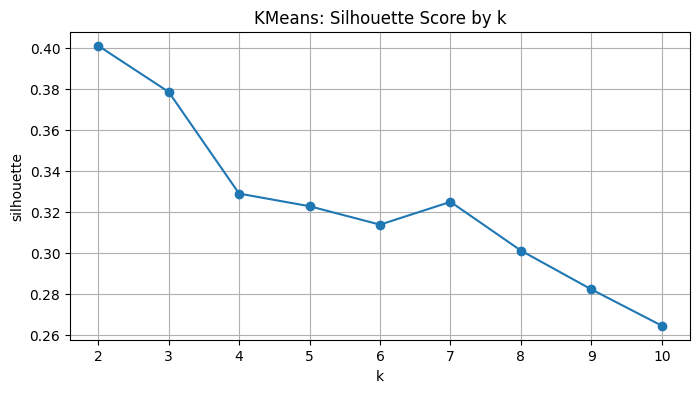

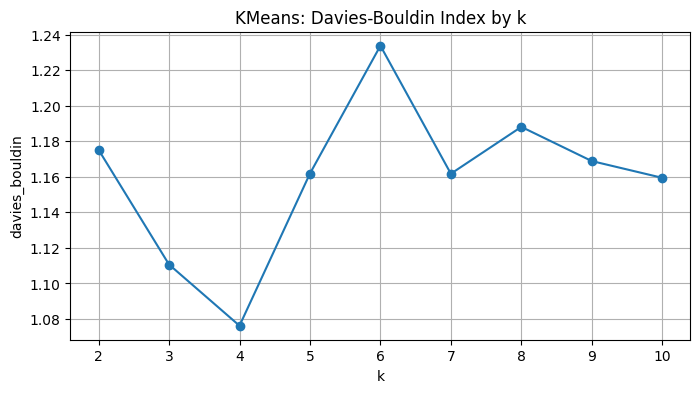

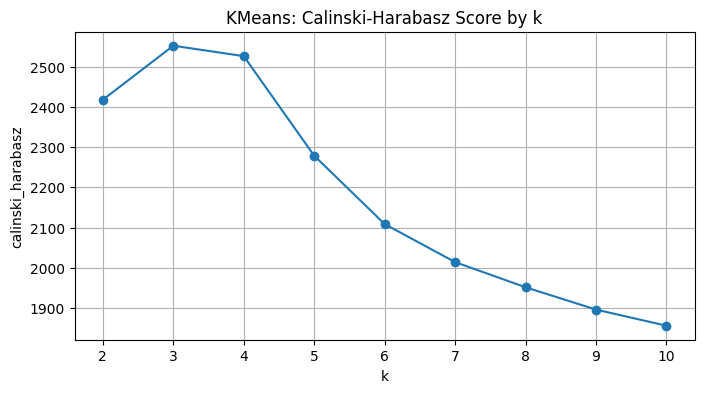


DBSCAN tuning table, sorted by silhouette


,eps,min_samples,cluster_count,noise_share,silhouette,davies_bouldin,calinski_harabasz
11,0.8,20,2,0.388833,0.553607,0.620495,1665.429077
3,0.4,20,2,0.978333,0.372485,0.885780,59.684193
7,0.6,20,2,0.634000,0.278380,0.739592,56.189133
10,0.8,15,6,0.330500,0.268874,0.750794,529.553505
15,1.0,20,6,0.205833,0.242085,0.804892,631.220590
24,2.0,5,4,0.009167,0.207909,1.626493,972.883403
18,1.3,15,5,0.077333,0.203909,1.192123,828.656335
14,1.0,15,6,0.170667,0.193511,0.920417,655.232640
19,1.3,20,5,0.091833,0.192693,1.088403,824.665035
23,1.6,20,5,0.048167,0.190396,1.229388,807.598989


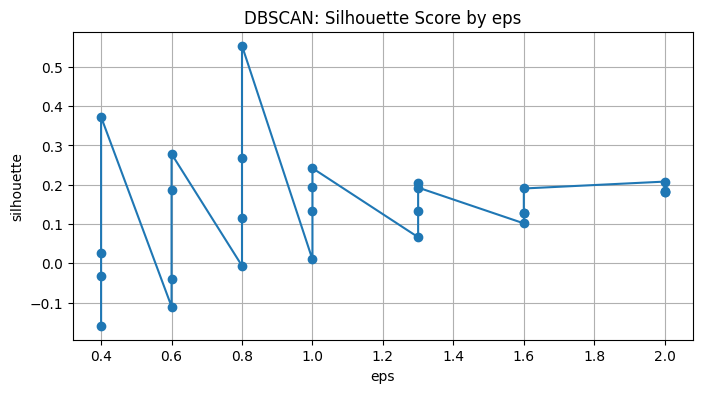

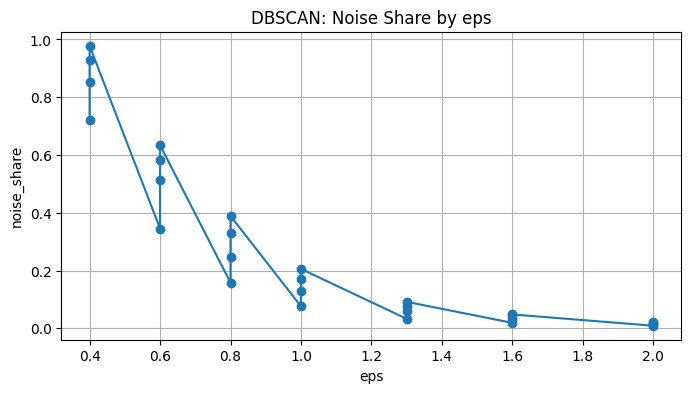

In [30]:
cluster_runs = [run for run in runs if run.get("model_family") == "clustering" and run.get("status") == "completed"]
latest_cluster_run = cluster_runs[0] if cluster_runs else None

if not latest_cluster_run:
    print("No completed clustering run found. Run /models/clusters/recompute first.")
else:
    cluster_metrics = latest_cluster_run.get("metrics", {})
    cluster_params = latest_cluster_run.get("selected_params", {})
    kmeans_df = pd.DataFrame(cluster_metrics.get("kmeans_trials", []))
    dbscan_df = pd.DataFrame(cluster_metrics.get("dbscan_trials", []))

    print("Latest completed clustering run:", latest_cluster_run.get("id"), latest_cluster_run.get("completed_at"))
    print("Selected parameters:")
    print(json.dumps(cluster_params, indent=2))

    print("\nKMeans tuning table")
    if not kmeans_df.empty:
        display(kmeans_df[["k", "silhouette", "davies_bouldin", "calinski_harabasz"]])
        optional_line_plot(kmeans_df, "k", "silhouette", "KMeans: Silhouette Score by k")
        optional_line_plot(kmeans_df, "k", "davies_bouldin", "KMeans: Davies-Bouldin Index by k")
        optional_line_plot(kmeans_df, "k", "calinski_harabasz", "KMeans: Calinski-Harabasz Score by k")

    print("\nDBSCAN tuning table, sorted by silhouette")
    if not dbscan_df.empty:
        display(
            dbscan_df.sort_values("silhouette", ascending=False, na_position="last")
            [["eps", "min_samples", "cluster_count", "noise_share", "silhouette", "davies_bouldin", "calinski_harabasz"]]
            .head(12)
        )
        optional_line_plot(
            dbscan_df.sort_values("eps"),
            "eps",
            "silhouette",
            "DBSCAN: Silhouette Score by eps",
        )
        optional_line_plot(
            dbscan_df.sort_values("eps"),
            "eps",
            "noise_share",
            "DBSCAN: Noise Share by eps",
        )


## 5. Cluster Interpretation

Metrics alone are not enough. A clustering result is useful only if it can be interpreted operationally. Here we summarize the bus reliability labels, delays, coverage, and hotspots.


,reliability_label,windows,mean_delay,p95_abs_delay,avg_coverage,hotspots,routes
1,low_realtime_coverage,489,-0.038200,1.224315,0.924564,76,107
0,delay_hotspot,752,0.421609,2.385186,0.966931,30,85
2,reliable,3557,0.184937,1.195836,0.979441,0,92
3,watch,1202,0.074060,1.117795,0.964451,0,108


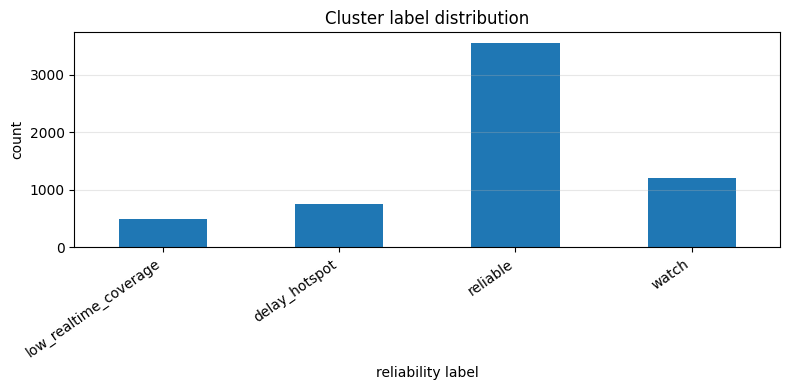

Hotspot examples


,route_short_name,stop_name,reliability_label,mean_delay_minutes,p95_abs_delay_minutes,prediction_coverage_ratio,latitude,longitude
0,52,Esikoisentie,delay_hotspot,0.49,2.31,0.982,60.251310,24.897070
1,52,Kaustisentie,delay_hotspot,0.56,2.29,0.982,60.238190,24.882780
2,56,Vaskisepäntie,delay_hotspot,0.31,2.28,0.985,60.221030,24.937070
3,118,Kirstin koulu,delay_hotspot,0.91,2.28,0.965,60.202460,24.669250
4,52,Kuopuksentie,delay_hotspot,0.42,2.27,0.985,60.254040,24.897320
5,52,Perhekunnantie,delay_hotspot,0.43,2.26,0.986,60.248740,24.894200
6,549,Valkonauhantie,delay_hotspot,0.72,2.24,0.968,60.220070,24.711160
7,549,Työväen Akatemia,delay_hotspot,0.69,2.23,0.979,60.222090,24.714630
8,52,Trumpettitie,delay_hotspot,0.47,2.22,0.990,60.240080,24.873600
9,52,Vanhempientie,delay_hotspot,0.36,2.22,0.985,60.256380,24.897630


Routes with most DBSCAN hotspot windows


,route_short_name,hotspot_count
0,52,17
1,92,6
2,94,6
3,95,6
4,165,5
5,80,5
6,549,4
7,159,4
8,88,4
9,81,3


In [31]:
if clusters_df.empty:
    print("No cluster assignments available for interpretation.")
else:
    label_summary = (
        clusters_df.groupby("reliability_label")
        .agg(
            windows=("stop_id", "count"),
            mean_delay=("mean_delay_minutes", "mean"),
            p95_abs_delay=("p95_abs_delay_minutes", "mean"),
            avg_coverage=("prediction_coverage_ratio", "mean"),
            hotspots=("dbscan_is_hotspot", "sum"),
            routes=("route_id", "nunique"),
        )
        .reset_index()
        .sort_values(["hotspots", "windows"], ascending=False)
    )
    display(label_summary)
    optional_bar_plot(label_summary.set_index("reliability_label")["windows"], "Cluster label distribution", "reliability label")

    hotspot_examples = clusters_df[clusters_df.get("dbscan_is_hotspot", False) == True]
    print("Hotspot examples")
    display(
        hotspot_examples[
            ["route_short_name", "stop_name", "reliability_label", "mean_delay_minutes", "p95_abs_delay_minutes", "prediction_coverage_ratio", "latitude", "longitude"]
        ].head(15)
    )

    route_hotspots = (
        hotspot_examples.groupby("route_short_name")
        .size()
        .sort_values(ascending=False)
        .head(12)
        .rename("hotspot_count")
        .reset_index()
    )
    print("Routes with most DBSCAN hotspot windows")
    display(route_hotspots)


## 6. Anomaly Detection Evaluation: Isolation Forest and LOF

The project does not have official labelled disruption/anomaly records. Therefore, evaluation uses transparent pseudo-labels.

Pseudo-label positives represent operationally suspicious bus windows:

- extreme delay windows;
- late-heavy windows;
- prediction coverage dropouts;
- stale feed windows.

The metrics are interpreted carefully:

- **Precision@K:** among the top-K highest-priority flags, how many overlap with pseudo-labels. Higher is better.
- **Recall:** how much of the pseudo-labelled suspicious behavior was captured. Higher is better, but may increase false alarms.
- **F1 proxy:** balance between precision and recall using pseudo-labels.
- **False-alarm share:** share of windows flagged without pseudo-label overlap. Lower is better operationally.


Latest completed anomaly run: 22 2026-04-28T14:13:02.547890+00:00
Selected parameters:
{
  "lof": {
    "n_neighbors": 20,
    "contamination": 0.05
  },
  "thresholds": {
    "feed_stale_threshold": 300.0,
    "late_anomaly_threshold": 1.0,
    "delay_anomaly_threshold": 7.7383,
    "coverage_dropout_threshold": 0.8571
  },
  "isolation_forest": {
    "max_samples": 256,
    "n_estimators": 100,
    "contamination": 0.05
  }
}

Isolation Forest evaluation, best rows by F1 proxy


,n_estimators,max_samples,contamination,precision_at_k,recall,f1_proxy,false_alarm_share
2,100,256,0.05,0.872,0.522782,0.653673,0.0064
8,100,auto,0.05,0.872,0.522782,0.653673,0.0064
11,200,256,0.05,0.848,0.508393,0.635682,0.0076
17,200,auto,0.05,0.848,0.508393,0.635682,0.0076
20,500,256,0.05,0.836,0.501199,0.626687,0.0082
26,500,auto,0.05,0.836,0.501199,0.626687,0.0082
5,100,512,0.05,0.828,0.496403,0.620690,0.0086
23,500,512,0.05,0.816,0.489209,0.611694,0.0092
14,200,512,0.05,0.804,0.482014,0.602699,0.0098
4,100,512,0.02,0.990,0.237410,0.382979,0.0002


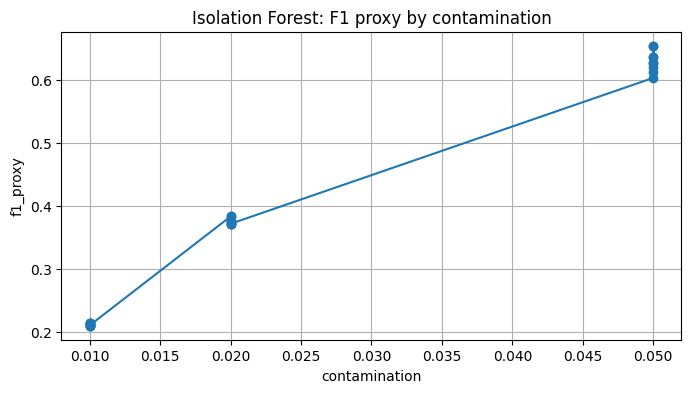


LOF evaluation, best rows by F1 proxy


,n_neighbors,contamination,precision_at_k,recall,f1_proxy,false_alarm_share
5,20,0.05,0.208,0.124700,0.155922,0.0396
2,10,0.05,0.192,0.115108,0.143928,0.0404
8,35,0.05,0.156,0.093525,0.116942,0.0422
11,50,0.05,0.096,0.057554,0.071964,0.0452
1,10,0.02,0.150,0.035971,0.058027,0.0170
4,20,0.02,0.100,0.023981,0.038685,0.0180
7,35,0.02,0.090,0.021583,0.034816,0.0182
0,10,0.01,0.080,0.009592,0.017131,0.0092
3,20,0.01,0.040,0.004796,0.008565,0.0096
6,35,0.01,0.040,0.004796,0.008565,0.0096


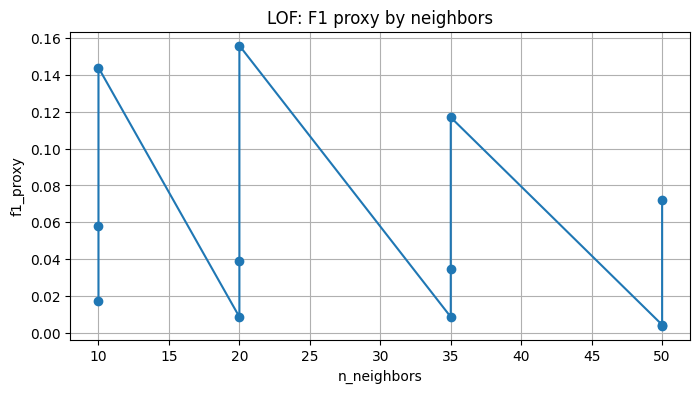

In [32]:
anomaly_runs = [run for run in runs if run.get("model_family") == "anomaly_detection" and run.get("status") == "completed"]
latest_anomaly_run = anomaly_runs[0] if anomaly_runs else None

if not latest_anomaly_run:
    print("No completed anomaly run found. Run /models/anomalies/recompute first.")
else:
    anomaly_metrics = latest_anomaly_run.get("metrics", {})
    anomaly_params = latest_anomaly_run.get("selected_params", {})
    if_trials = pd.DataFrame(anomaly_metrics.get("isolation_forest_trials", []))
    lof_trials = pd.DataFrame(anomaly_metrics.get("lof_trials", []))

    print("Latest completed anomaly run:", latest_anomaly_run.get("id"), latest_anomaly_run.get("completed_at"))
    print("Selected parameters:")
    print(json.dumps(anomaly_params, indent=2))

    print("\nIsolation Forest evaluation, best rows by F1 proxy")
    if not if_trials.empty:
        display(
            if_trials.sort_values(["f1_proxy", "precision_at_k"], ascending=False)
            [["n_estimators", "max_samples", "contamination", "precision_at_k", "recall", "f1_proxy", "false_alarm_share"]]
            .head(12)
        )
        optional_line_plot(
            if_trials.sort_values("contamination"),
            "contamination",
            "f1_proxy",
            "Isolation Forest: F1 proxy by contamination",
        )

    print("\nLOF evaluation, best rows by F1 proxy")
    if not lof_trials.empty:
        display(
            lof_trials.sort_values(["f1_proxy", "precision_at_k"], ascending=False)
            [["n_neighbors", "contamination", "precision_at_k", "recall", "f1_proxy", "false_alarm_share"]]
            .head(12)
        )
        optional_line_plot(
            lof_trials.sort_values("n_neighbors"),
            "n_neighbors",
            "f1_proxy",
            "LOF: F1 proxy by neighbors",
        )


## 7. Anomaly Interpretation

This section connects anomaly scores to actual route/stop examples. These are best interpreted as a **watchlist**, not confirmed disruptions, because official disruption labels are not available.


,reason,count
0,coverage dropout,1239
1,stale feed,992
2,model flagged unusual pattern,570
3,extreme delay,373
4,late-heavy window,134
5,"extreme delay, late-heavy window",98
6,"extreme delay, coverage dropout",26
7,"coverage dropout, stale feed",25
8,"late-heavy window, stale feed",10
9,"late-heavy window, coverage dropout",5


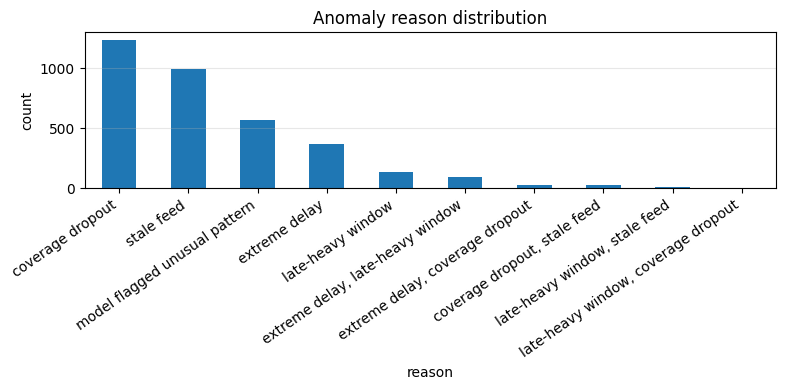

Routes with most recent anomaly windows


,route_short_name,anomaly_windows,mean_delay,avg_coverage,stops
0,841,128,1.694141,0.971102,108
1,788K,101,8.056238,0.987416,100
2,520,96,1.941250,0.958313,43
3,641,78,1.296667,0.953551,60
4,623,77,-1.039870,0.965636,55
5,717,70,2.913429,0.946243,45
6,739,65,2.066154,0.936785,55
7,842,59,0.828983,0.957000,48
8,986,56,-0.117857,0.985375,54
9,345,56,0.117321,0.983714,56


Example anomaly rows for presentation


,bucket,route_short_name,stop_name,anomaly_reason,mean_delay_minutes,prediction_coverage_ratio,isolation_forest_is_anomaly,lof_is_anomaly,latitude,longitude
0,2026-04-28T14:00:00+00:00,901,Bobäcks skola,model flagged unusual pattern,-4.23,1.0,False,True,60.176757,24.545682
1,2026-04-28T14:00:00+00:00,623,Havukallionkatu,model flagged unusual pattern,0.96,1.0,False,True,60.321330,25.061670
2,2026-04-28T14:00:00+00:00,571,Vaskivuorentie,model flagged unusual pattern,0.97,1.0,False,True,60.264210,24.843060
3,2026-04-28T14:00:00+00:00,631,Laulurastaanpolku,model flagged unusual pattern,1.03,1.0,False,True,60.345710,25.056060
4,2026-04-28T14:00:00+00:00,173Z,Kolsari,model flagged unusual pattern,2.32,1.0,False,True,60.102684,24.430943
5,2026-04-28T14:00:00+00:00,571,Orvokkitie,model flagged unusual pattern,0.69,1.0,False,True,60.292714,25.035197
6,2026-04-28T14:00:00+00:00,631,Peltomyyränkuja,model flagged unusual pattern,2.27,1.0,False,True,60.352538,25.084276
7,2026-04-28T14:00:00+00:00,173Z,Syväjärvi,model flagged unusual pattern,2.42,1.0,False,True,60.100687,24.421182
8,2026-04-28T14:00:00+00:00,583K,Läntinen teollisuusk,model flagged unusual pattern,1.03,1.0,False,True,60.278710,24.758940
9,2026-04-28T14:00:00+00:00,583K,Suopuronrinne,model flagged unusual pattern,1.03,1.0,False,True,60.286180,24.736940


In [33]:
if anomalies_df.empty:
    print("No recent anomaly records available. If Docker was restarted, run anomaly recompute and refresh the notebook.")
else:
    reason_summary = anomalies_df["anomaly_reason"].fillna("model flagged unusual pattern").value_counts().rename_axis("reason").reset_index(name="count")
    display(reason_summary)
    optional_bar_plot(reason_summary.set_index("reason")["count"].head(10), "Anomaly reason distribution", "reason")

    route_anomaly_summary = (
        anomalies_df.groupby("route_short_name")
        .agg(
            anomaly_windows=("stop_id", "count"),
            mean_delay=("mean_delay_minutes", "mean"),
            avg_coverage=("prediction_coverage_ratio", "mean"),
            stops=("stop_id", "nunique"),
        )
        .sort_values("anomaly_windows", ascending=False)
        .head(12)
        .reset_index()
    )
    print("Routes with most recent anomaly windows")
    display(route_anomaly_summary)

    display_cols = [
        "bucket", "route_short_name", "stop_name", "anomaly_reason", "mean_delay_minutes",
        "prediction_coverage_ratio", "isolation_forest_is_anomaly", "lof_is_anomaly", "latitude", "longitude",
    ]
    print("Example anomaly rows for presentation")
    display(anomalies_df[[col for col in display_cols if col in anomalies_df.columns]].head(15))


## 8. Spatial Visualizations With Static Plots And CartoDB Map Layer

These visualizations support the dashboard evidence.

The first part uses static longitude/latitude plots with a CartoDB Positron basemap when `contextily` is installed. 

The second part builds an **interactive Folium map using a CartoDB Positron basemap**. That map is more presentation-friendly because it gives geographic context: roads, neighborhoods, route-stop locations, DBSCAN hotspots, and anomaly watchlist points can be inspected as layers.

If the interactive map does not appear, install notebook dependencies first:

```powershell
pip install -r requirements-notebooks.txt
```


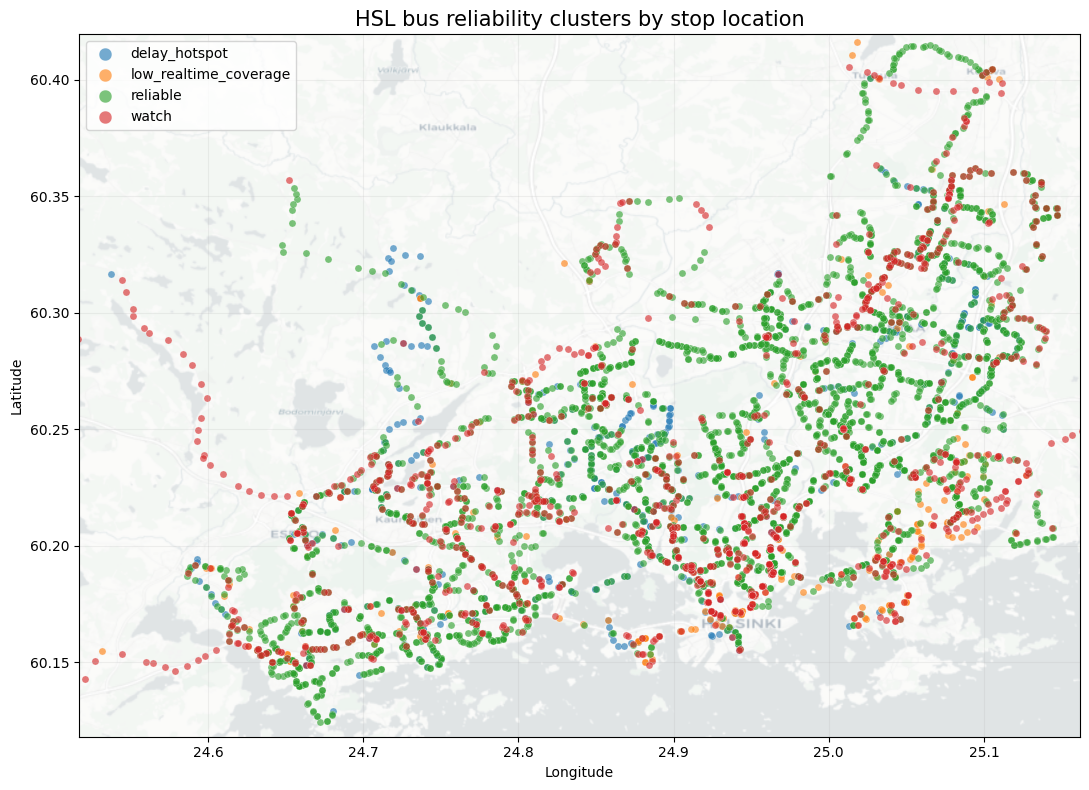

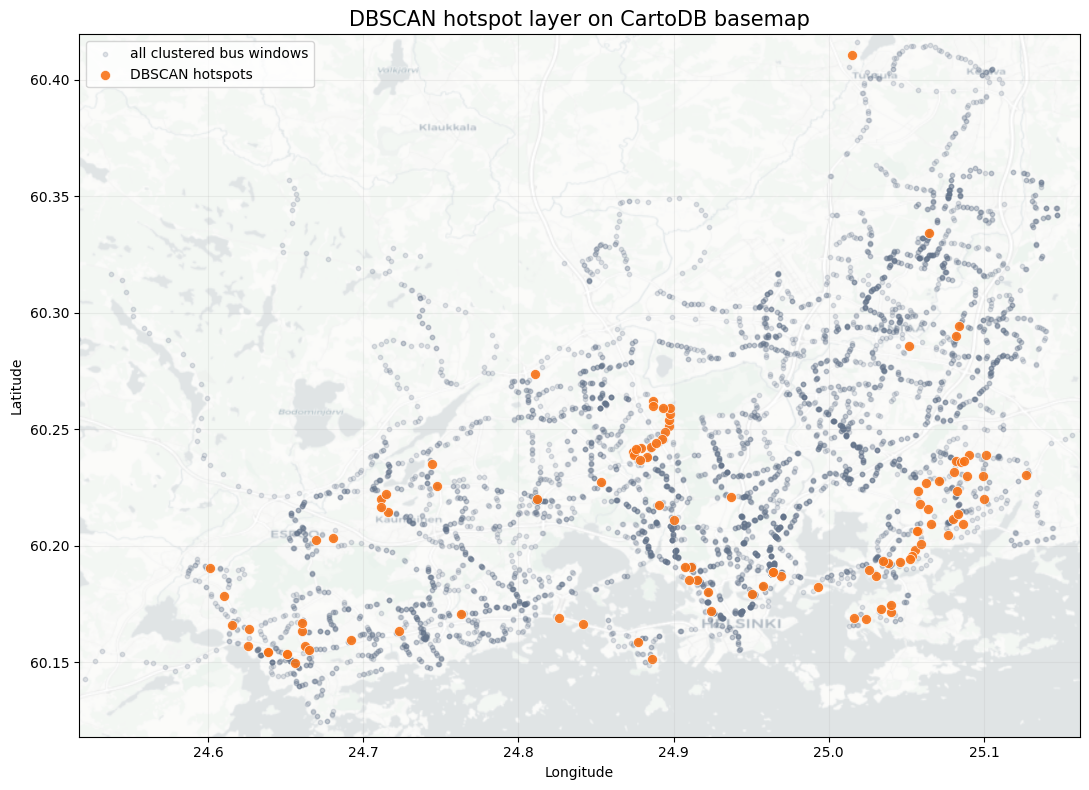

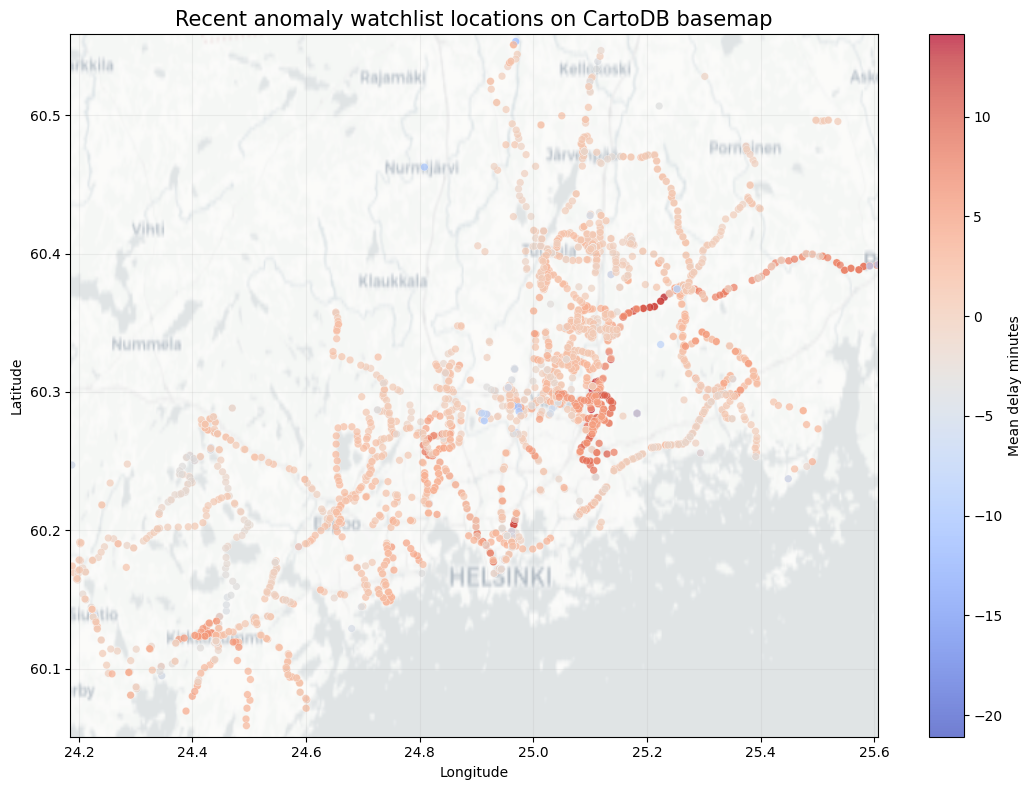

Interactive CartoDB map saved to: reports\maps\part4_hsl_bus_reliability_carto_map.html


In [34]:
if plt is not None and not clusters_df.empty:
    fig, ax = plt.subplots(figsize=(11, 8))
    label_colors = {
        "delay_hotspot": "#1f77b4",
        "low_realtime_coverage": "#ff7f0e",
        "reliable": "#2ca02c",
        "watch": "#d62728",
    }
    ax.set_xlim(clusters_df["longitude"].quantile(0.005) - 0.015, clusters_df["longitude"].quantile(0.995) + 0.015)
    ax.set_ylim(clusters_df["latitude"].quantile(0.005) - 0.015, clusters_df["latitude"].quantile(0.995) + 0.015)
    add_carto_basemap(ax)
    for label, group in clusters_df.groupby("reliability_label"):
        ax.scatter(
            group["longitude"],
            group["latitude"],
            s=26,
            alpha=0.62,
            label=label,
            color=label_colors.get(label, "#64748b"),
            edgecolor="white",
            linewidth=0.25,
        )
    ax.set_title("HSL bus reliability clusters by stop location", fontsize=15)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.legend(markerscale=1.8, frameon=True, loc="upper left")
    ax.grid(alpha=0.18)
    plt.tight_layout()
    plt.show()

if plt is not None and not clusters_df.empty and "dbscan_is_hotspot" in clusters_df.columns:
    hotspots = clusters_df[clusters_df["dbscan_is_hotspot"] == True]
    fig, ax = plt.subplots(figsize=(11, 8))
    ax.set_xlim(clusters_df["longitude"].quantile(0.005) - 0.015, clusters_df["longitude"].quantile(0.995) + 0.015)
    ax.set_ylim(clusters_df["latitude"].quantile(0.005) - 0.015, clusters_df["latitude"].quantile(0.995) + 0.015)
    add_carto_basemap(ax)
    ax.scatter(
        clusters_df["longitude"],
        clusters_df["latitude"],
        s=10,
        alpha=0.20,
        color="#64748b",
        label="all clustered bus windows",
    )
    ax.scatter(
        hotspots["longitude"],
        hotspots["latitude"],
        s=52,
        alpha=0.9,
        color="#f97316",
        edgecolor="white",
        linewidth=0.5,
        label="DBSCAN hotspots",
    )
    ax.set_title("DBSCAN hotspot layer on CartoDB basemap", fontsize=15)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.legend(frameon=True, loc="upper left")
    ax.grid(alpha=0.18)
    plt.tight_layout()
    plt.show()

if plt is not None and not anomalies_df.empty:
    fig, ax = plt.subplots(figsize=(11, 8))
    ax.set_xlim(anomalies_df["longitude"].quantile(0.005) - 0.015, anomalies_df["longitude"].quantile(0.995) + 0.015)
    ax.set_ylim(anomalies_df["latitude"].quantile(0.005) - 0.015, anomalies_df["latitude"].quantile(0.995) + 0.015)
    add_carto_basemap(ax)
    scatter = ax.scatter(
        anomalies_df["longitude"],
        anomalies_df["latitude"],
        s=30,
        alpha=0.72,
        c=anomalies_df["mean_delay_minutes"],
        cmap="coolwarm",
        edgecolor="white",
        linewidth=0.25,
    )
    plt.colorbar(scatter, ax=ax, label="Mean delay minutes")
    ax.set_title("Recent anomaly watchlist locations on CartoDB basemap", fontsize=15)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(alpha=0.18)
    plt.tight_layout()
    plt.show()

# Interactive CartoDB map layer for presentation and richer interpretation.
if folium is None:
    print("Interactive CartoDB map skipped because folium is not installed.")
elif clusters_df.empty and anomalies_df.empty:
    print("Interactive CartoDB map skipped because no cluster/anomaly coordinates are available.")
else:
    map_source = clusters_df if not clusters_df.empty else anomalies_df
    center_lat = float(map_source["latitude"].dropna().mean()) if "latitude" in map_source else 60.1699
    center_lon = float(map_source["longitude"].dropna().mean()) if "longitude" in map_source else 24.9384

    hsl_map = folium.Map(
        location=[center_lat, center_lon],
        zoom_start=10,
        tiles="CartoDB positron",
        control_scale=True,
    )
    folium.TileLayer("CartoDB dark_matter", name="CartoDB dark matter").add_to(hsl_map)
    folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(hsl_map)

    label_colors = {
        "reliable": "#14b8a6",
        "watch": "#f59e0b",
        "delay_hotspot": "#ef4444",
        "low_realtime_coverage": "#2563eb",
    }

    if not clusters_df.empty:
        cluster_layer = folium.FeatureGroup(name="Reliability clusters", show=True)
        cluster_sample = clusters_df.sample(min(len(clusters_df), 1200), random_state=7) if len(clusters_df) > 1200 else clusters_df
        for row in cluster_sample.itertuples(index=False):
            label = getattr(row, "reliability_label", "watch")
            color = label_colors.get(label, "#64748b")
            popup = folium.Popup(
                f"<b>Route:</b> {getattr(row, 'route_short_name', '')}<br>"
                f"<b>Stop:</b> {getattr(row, 'stop_name', '')}<br>"
                f"<b>Label:</b> {str(label).replace('_', ' ')}<br>"
                f"<b>Mean delay:</b> {getattr(row, 'mean_delay_minutes', 0):.2f} min<br>"
                f"<b>Coverage:</b> {getattr(row, 'prediction_coverage_ratio', 0) * 100:.1f}%",
                max_width=260,
            )
            folium.CircleMarker(
                location=[getattr(row, "latitude"), getattr(row, "longitude")],
                radius=4,
                color=color,
                fill=True,
                fill_color=color,
                fill_opacity=0.62,
                weight=1,
                popup=popup,
            ).add_to(cluster_layer)
        cluster_layer.add_to(hsl_map)

        hotspot_layer = folium.FeatureGroup(name="DBSCAN hotspots", show=True)
        hotspots = clusters_df[clusters_df.get("dbscan_is_hotspot", False) == True]
        for row in hotspots.itertuples(index=False):
            popup = folium.Popup(
                f"<b>DBSCAN hotspot</b><br>"
                f"<b>Route:</b> {getattr(row, 'route_short_name', '')}<br>"
                f"<b>Stop:</b> {getattr(row, 'stop_name', '')}<br>"
                f"<b>Mean delay:</b> {getattr(row, 'mean_delay_minutes', 0):.2f} min<br>"
                f"<b>P95 abs delay:</b> {getattr(row, 'p95_abs_delay_minutes', 0):.2f} min",
                max_width=260,
            )
            folium.CircleMarker(
                location=[getattr(row, "latitude"), getattr(row, "longitude")],
                radius=7,
                color="#f97316",
                fill=True,
                fill_color="#f97316",
                fill_opacity=0.9,
                weight=2,
                popup=popup,
            ).add_to(hotspot_layer)
        hotspot_layer.add_to(hsl_map)

    if not anomalies_df.empty:
        anomaly_layer = folium.FeatureGroup(name="Anomaly watchlist", show=True)
        anomaly_sample = anomalies_df.head(800)
        marker_target = MarkerCluster(name="Clustered anomaly markers") if MarkerCluster is not None else anomaly_layer
        for row in anomaly_sample.itertuples(index=False):
            reason = getattr(row, "anomaly_reason", "model flagged unusual pattern")
            popup = folium.Popup(
                f"<b>Anomaly watchlist</b><br>"
                f"<b>Route:</b> {getattr(row, 'route_short_name', '')}<br>"
                f"<b>Stop:</b> {getattr(row, 'stop_name', '')}<br>"
                f"<b>Reason:</b> {reason}<br>"
                f"<b>Mean delay:</b> {getattr(row, 'mean_delay_minutes', 0):.2f} min<br>"
                f"<b>Coverage:</b> {getattr(row, 'prediction_coverage_ratio', 0) * 100:.1f}%",
                max_width=280,
            )
            folium.CircleMarker(
                location=[getattr(row, "latitude"), getattr(row, "longitude")],
                radius=5,
                color="#dc2626",
                fill=True,
                fill_color="#dc2626",
                fill_opacity=0.75,
                weight=1,
                popup=popup,
            ).add_to(marker_target)
        if MarkerCluster is not None:
            marker_target.add_to(anomaly_layer)
        anomaly_layer.add_to(hsl_map)

    folium.LayerControl(collapsed=False).add_to(hsl_map)

    output_dir = Path("reports/maps")
    output_dir.mkdir(parents=True, exist_ok=True)
    output_path = output_dir / "part4_hsl_bus_reliability_carto_map.html"
    hsl_map.save(output_path)
    print(f"Interactive CartoDB map saved to: {output_path}")
    display(hsl_map)


## 9. Interpretation of Model Performance

### Clustering

The clustering metrics show whether the bus reliability windows form meaningful groups. A good result is not only a high score; it must also be explainable in transport terms. In this project, the cluster labels such as `reliable`, `watch`, `delay_hotspot`, and `low_realtime_coverage` are useful because they connect model output to operational questions.

### DBSCAN Hotspots

DBSCAN is especially useful because it does not force every bus stop/window into a cluster. It identifies dense reliability problem areas and leaves weaker/noisier points outside hotspot clusters. This is useful for planners because reliability issues often appear around specific corridors, terminals, and road sections.

### Anomaly Detection

Isolation Forest and LOF are interpreted as a watchlist. High precision is valuable because planners should not be overloaded with false alarms. Recall is also useful, but in a live operations dashboard a slightly lower recall can be acceptable if the alerts that do appear are credible and explainable.

### Trade-off

The main trade-off is between catching more suspicious windows and avoiding too many false alarms. A higher contamination value usually increases recall but may also increase false alarms. This is why the notebook reports both `Precision@K` and `false_alarm_share`.


## 10. Implications for Urban Mobility

The evaluation supports practical urban mobility decisions:

- **Route planning:** repeated hotspot corridors can be reviewed for timetable padding, signal priority, bus-lane design, or stop-spacing issues.
- **Operations monitoring:** anomaly windows can become a live watchlist for dispatchers or analysts.
- **Data quality improvement:** low prediction coverage and stale feed windows reveal where realtime data reliability needs attention.
- **Public communication:** route-level OTP, delay, and coverage summaries help explain reliability in a way non-technical stakeholders understand.
- **Future modelling:** once more GTFS-RT history is collected, these features can support supervised delay prediction or ETA models.


## 11. Limitations

The limitations are important and should be stated honestly in the report/presentation.

- GTFS-RT history is limited because it only accumulates while the local poller is running.
- HSL realtime messages may not always provide stable static `trip_id` values.
- Missing GTFS-RT TripUpdates are not the same as buses being on time.
- Pseudo-labels are not official ground-truth anomaly labels.
- The dashboard is bus-only by design; results should not be generalized to metro, tram, rail, or ferry.
- The model is strongest for pattern discovery and monitoring, not yet for prediction.

These limitations do not invalidate the project we made. They show that the Minimum Viable Product is honest about uncertainty and ready for future improvement.


## 12. Part 4 Conclusion

Part 4 demonstrates that the project evaluates the chosen data-mining techniques using appropriate metrics and connects the results to urban mobility decisions.

The main conclusion is:

> HSL bus GTFS and GTFS-RT data can be transformed into interpretable route-stop-hour reliability features. Clustering reveals recurring reliability patterns and hotspot areas, while anomaly detection creates a live watchlist of unusual bus operation windows. The system is useful for exploratory transit reliability analysis, especially when supported by the interactive dashboard.
